# 05 · Automation opportunities and the business case

**Data:** **[REAL]** topic volumes, complexity proxies and response breaches from the 2023 export (2,330 tickets) · **[ASSUMPTION]** deflection rates, costs and alert catch rates (`config.yaml`) · **[SYNTHETIC]** agent-hours, FTE and simulated response SLA from the 20× scale-up (notebook 04).

In [1]:
import json, pandas as pd, plotly.io as pio
pio.renderers.default = "notebook_connected+png"     # interactive in HTML export, static PNG fallback for GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 1000, None
from support_ops import charts as C
from support_ops.data import load_processed, load_tickets
from support_ops.config import load_config, REPO_ROOT
kn = json.load(open(REPO_ROOT / "reports" / "key_numbers.json"))
cfg = load_config()

# notebook 05 additions
import numpy as np
from support_ops import automation, interactive, rca
from support_ops.sql import run_sql_file
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)


def check(value, key, d=4):
    """Recomputed value must equal reports/key_numbers.json to d decimals (the precision it is stored at)."""
    assert abs(value - kn[key]) <= 0.5 * 10 ** -d + 1e-9, f"{key}: recomputed {value!r} vs key_numbers {kn[key]!r}"
    return value


def P(x, d=1):
    """Share -> percentage text, e.g. 0.8761 -> '87.6%'."""
    return f"{100 * x:.{d}f}%"

## TL;DR

- **[REAL] Demand is spread out, so no single fix removes most of the volume:** the top 2 of 7 topics are 49.6% of tickets. Complexity proxies differ little between topics, so automation candidates are chosen by volume and by request type: pricing & licensing and purchasing & invoicing (self-service), and feature requests (route to a product feedback portal).
- **[ASSUMPTION × SYNTHETIC] Base-case deflection takes 19.7% of tickets out of the agent queue** (459 of the 2,330 in the export): about 86 agent-hours a week at 20× scale and 4 FTE of capacity (range 3–7). We treat it as capacity to redeploy to the stale-ticket sweep, resolution work or growth, not as a saving.
- **[SYNTHETIC] Options for the same 23-FTE planning desk** (response SLA, optimistic / conservative rule; status quo 85.8% / 82.6%): **A. hire** 1.4 FTE of weekend shifts, €94k in year one → 87.6% / 85.5%; **B. re-roster**, €0 → 87.6% / 84.7%; **C. automate**, €65k → 87.7% / 86.3%; **B + C**, €65k → 87.9% / 86.8%. Re-rostering gets most of what hiring gets, at no cost.
- **None of these options lifts the process ceiling (~87.8%) or touches resolution SLA.** A pickup fix does: a 45-minute "unanswered email" alert aimed at the 103 real email breaches (a median 3.5 hours late) would add +1.1 / +2.2 / +3.3 points at a 25 / 50 / 75% catch rate. It is a pilot, not stacked onto the options.
- **Recommendation:** no headcount request this quarter. Re-roster once today's real roster is confirmed; pilot self-service for pricing/licensing and invoicing, feedback-portal routing for feature requests, and the email alert. Take no SLA credit until deflection and catch rates are measured.

In [2]:
print(f"[REAL] Top {kn['pareto_top20pct_topics_n']} topics = {P(kn['pareto_top20pct_topics_share'])} of tickets")
print(f"[ASSUMPTION x SYNTHETIC] Base deflection {P(kn['auto_deflected_share_base'])} of tickets "
      f"({kn['auto_real_tickets_deflected_base']:.0f} of {kn['real_tickets']:,}); {kn['auto_hours_saved_week_base']:.0f} agent-hours/week; "
      f"{kn['auto_fte_freed_base']} FTE of capacity (range {kn['auto_fte_freed_low']}-{kn['auto_fte_freed_high']})")
for name, key, cost_key in [("Status quo", "bc_status_quo_sl", None), ("A. Hire", "bc_hire_sl", "bc_hire_first_year_eur"),
                            ("B. Re-roster", "bc_reroster_sl", None), ("C. Automate", "bc_automate_sl", "bc_automation_first_year_eur"),
                            ("B + C", "bc_combined_sl", "bc_automation_first_year_eur")]:
    year1 = f"EUR {kn[cost_key]:,}" if cost_key else "EUR 0"
    print(f"[SYNTHETIC] {name:13s} response SLA {P(kn[key])} optimistic / {P(kn[key + '_sum'])} conservative; year-1 cost {year1}")
print(f"Process ceiling {P(kn['staff_process_ceiling'])}; hire = {kn['staff_hire_extra_fte_equiv_by_day']:.1f} FTE of weekend shifts")
print(f"[REAL x ASSUMPTION] Email alert: {kn['email_breaches']} breaches, median {kn['late_email_breach_median_min_late'] / 60:.1f} h late; "
      f"uplift +{kn['email_alert_uplift_pp_low']:.1f} / +{kn['email_alert_uplift_pp_base']:.1f} / +{kn['email_alert_uplift_pp_high']:.1f} pts "
      f"at 25 / 50 / 75% catch")

[REAL] Top 2 topics = 49.6% of tickets
[ASSUMPTION x SYNTHETIC] Base deflection 19.7% of tickets (459 of 2,330); 86 agent-hours/week; 4 FTE of capacity (range 3-7)
[SYNTHETIC] Status quo    response SLA 85.8% optimistic / 82.6% conservative; year-1 cost EUR 0
[SYNTHETIC] A. Hire       response SLA 87.6% optimistic / 85.5% conservative; year-1 cost EUR 94,000
[SYNTHETIC] B. Re-roster  response SLA 87.6% optimistic / 84.7% conservative; year-1 cost EUR 0
[SYNTHETIC] C. Automate   response SLA 87.7% optimistic / 86.3% conservative; year-1 cost EUR 65,000
[SYNTHETIC] B + C         response SLA 87.9% optimistic / 86.8% conservative; year-1 cost EUR 65,000
Process ceiling 87.8%; hire = 1.4 FTE of weekend shifts
[REAL x ASSUMPTION] Email alert: 103 breaches, median 3.5 h late; uplift +1.1 / +2.2 / +3.3 pts at 25 / 50 / 75% catch


## Question

From the Director's request (*"Is there a way to fix this without adding people?"* and *"I have to put in a headcount request and need data to back it up"*), as scoped in `docs/01_request_and_scope.md`:

- **Q6b.** How many tickets could self-service or automation deflect, and how many agent-hours would that save?
- **Q6c.** Which process fix targets the actual cause of response breaches?
- **Q7.** What does each option (hire, re-roster, automate) cost, and what response SLA does it buy? Which do we recommend for next quarter?

Resolution SLA, the SLA that fell, is not moved by any option here. Its fixes (the stale-ticket sweep and finding the resolution slow path) come from the root-cause work in notebook 03.

## Data

**[REAL]** tables come from the export; **[SYNTHETIC]** ones from the 20× scale-up of notebook 04; **[ASSUMPTION]** inputs from `config.yaml`. All tables were written by `python run.py` (`support_ops.pipeline.run`); the producing function is listed. Numbers in the text come from `reports/key_numbers.json` (printed and cross-checked in code cells); a few supporting numbers are computed in the cell just above the text that quotes them.

In [3]:
tables = {
    "fct_tickets": ("REAL", "data.build_fct_tickets (sql/00_fct_tickets.sql)"),
    "kpi_topic_pareto": ("REAL", "kpis.build_kpis (sql/07_topic_pareto.sql)"),
    "topic_profile": ("REAL + ASSUMPTION", "automation.topic_profile"),
    "rca_breach_lateness": ("REAL", "rca.breach_lateness"),
    "rca_email_alert": ("REAL + ASSUMPTION", "rca.email_alert_lever"),
    "synth_work_items": ("SYNTHETIC", "synth.build_work_items"),
    "staff_demand": ("SYNTHETIC", "staffing.demand_by_how"),
    "automation_by_topic": ("SYNTHETIC + ASSUMPTION", "automation.automation_impact"),
    "automation_summary": ("SYNTHETIC + ASSUMPTION", "automation.automation_impact"),
    "business_options": ("SYNTHETIC + ASSUMPTION", "business_case.options"),
}
D = {name: (load_tickets() if name == "fct_tickets" else load_processed(name)) for name in tables}
pd.DataFrame([{"table": n, "source": s, "produced by": f, "rows": len(D[n])} for n, (s, f) in tables.items()])

,table,source,produced by,rows
0,fct_tickets,REAL,data.build_fct_tickets (sql/00_fct_tickets.sql),2330
1,kpi_topic_pareto,REAL,kpis.build_kpis (sql/07_topic_pareto.sql),31
2,topic_profile,REAL + ASSUMPTION,automation.topic_profile,7
3,rca_breach_lateness,REAL,rca.breach_lateness,3
4,rca_email_alert,REAL + ASSUMPTION,rca.email_alert_lever,3
5,synth_work_items,SYNTHETIC,synth.build_work_items,202172
6,staff_demand,SYNTHETIC,staffing.demand_by_how,168
7,automation_by_topic,SYNTHETIC + ASSUMPTION,automation.automation_impact,21
8,automation_summary,SYNTHETIC + ASSUMPTION,automation.automation_impact,3
9,business_options,SYNTHETIC + ASSUMPTION,business_case.options,5


In [4]:
display(pd.Series(cfg["cost"], name="config.yaml -> cost (EUR)").to_frame())     # ASSUMPTIONS, to confirm with Finance
pd.DataFrame([{"topic": t, "lever": v["lever"], "low": v["deflection"][0], "base": v["deflection"][1],
               "high": v["deflection"][2]} for t, v in cfg["automation"]["topics"].items()])   # ASSUMPTIONS

,config.yaml -> cost (EUR)
fte_annual_eur,60000
hire_one_off_eur,5000
automation_one_off_eur,40000
automation_annual_eur,25000


,topic,lever,low,base,high
0,Pricing and licensing,"Pricing & licensing FAQ + self-service license portal (keys, seats, renewals)",0.10,0.20,0.30
1,Purchasing and invoicing,"Billing portal: invoice download, payment status, PO / address changes",0.15,0.25,0.35
2,Product setup,Guided setup articles + in-app onboarding checklist,0.05,0.15,0.25
3,Feature request,Route to product feedback portal with auto-acknowledgement (not support work),0.25,0.40,0.60
4,Training request,Training catalogue + booking form,0.25,0.40,0.60
5,Bug report,None (needs investigation); status page for known issues only,0.00,0.00,0.05
6,Other,None identified,0.00,0.00,0.05


## Method

**1 · Where the volume is [REAL].** Pareto of tickets by topic, computed in SQL (`sql/07_topic_pareto.sql`, printed below and re-run in Results §1).

**2 · How complex each topic is [REAL].** Three proxies per topic, from the export: mean agent interactions, share handled by tier 2, median resolution time. The complexity index is the average of their percentile ranks across topics (0 = simplest topic, 1 = most complex; `automation.topic_profile`):

$$\text{complexity}_{\text{topic}} = \tfrac{1}{3}\Big[\operatorname{pctrank}(\text{interactions}) + \operatorname{pctrank}(\text{tier-2 share}) + \operatorname{pctrank}(\text{median resolution time})\Big]$$

**3 · Levers and deflection rates [ASSUMPTION].** For each topic, a lever (self-service content, a portal, routing out of support) and a low / base / high share $r_{\text{topic}}$ of that topic's tickets it would take out of the agent queue (`config.yaml → automation.topics`, shown above). The rates are not in the data; a pilot has to measure them.

**4 · Agent-hours and FTE [SYNTHETIC].** Each topic's weekly agent-hours come from the synthetic work items of notebook 04 (same topic mix, 20× volume):

$$\text{agent-hours saved per week} = \sum_{\text{topics}} r_{\text{topic}} \times \text{agent-hours per week}_{\text{topic}}$$

For the FTE effect, `automation.automation_impact` removes that share of each topic's synthetic tickets (with their work items) and re-runs demand → hourly requirement → cheapest roster, exactly as in notebook 04. The dashboard's what-if (`interactive.deflection_whatif`) approximates the same by scaling every hour's demand down by the workload removed; it is used below as a cross-check.

**5 · Business case [SYNTHETIC × ASSUMPTION].** Five options from the same starting point: the 23-FTE desk of the 20× scenario with today's roster assumed weekday-weighted (`business_case.options`). **0. Status quo**; **A. Hire**: keep today's roster and add the weekend shifts that close every gap; **B. Re-roster**: same people, workload-matched roster; **C. Automate**: base-case deflection, roster unchanged; **B + C**. Response SLA comes from simulating the same synthetic year (the automation options on the deflected year), under both response-time rules of notebook 04. Costs are assumptions: hiring is costed in FTE-equivalents of the shifts actually needed plus a one-off cost per whole hire; first-year cost = one-off + annual change.

**6 · Email alert [REAL × ASSUMPTION].** An alert fires when an email is unanswered at 45 minutes. If it gets a share of today's late emails (the catch rate, unknown) answered within the 60-minute target (`rca.email_alert_lever`):

$$\mathrm{SL}_{\text{after}} = \mathrm{SL}_{\text{now}} + \frac{\text{email breaches} \times \text{catch rate}}{\text{tickets with a response outcome}}$$

The breach counts are real; the catch rate (25 / 50 / 75%) is the assumption.

> **How to read this.** Deflection and the alert work on different things. Deflection removes work, so the same team has more spare capacity; it lifts response SLA only where people were queueing. The alert attacks the pickup failures that cap response SLA no matter how many people are on shift.

In [5]:
print((REPO_ROOT / "sql" / "07_topic_pareto.sql").read_text())

-- =============================================================================
-- 07_topic_pareto.sql  ·  Pareto of ticket categories
-- -----------------------------------------------------------------------------
-- Input : fct_tickets (variable `fct_tickets_path`)
-- Output: two levels in one long table:
--         level = 'topic'           (7 categories)
--         level = 'topic x product' (topic x product group, 24 non-empty cells)
--         with tickets, share, cumulative share, rank and rank percentile
--         (rank_pct <= 0.20 = "top 20% of categories").
-- Run: python -m support_ops.sql sql/07_topic_pareto.sql
-- =============================================================================
WITH f AS (
    SELECT * FROM read_parquet(coalesce(getvariable('fct_tickets_path'), 'data/processed/fct_tickets.parquet'))
),
cats AS (
    SELECT 'topic' AS level, topic AS category, count(*) AS tickets,
           median(agent_interactions) AS interactions_median,
           avg((a

## Results

### 1. Where the volume is [REAL]

The Pareto SQL re-run on the cleaned export, checked against the cached table and key numbers:

Top 2 of 7 topics (top 20%) = 49.6% of tickets


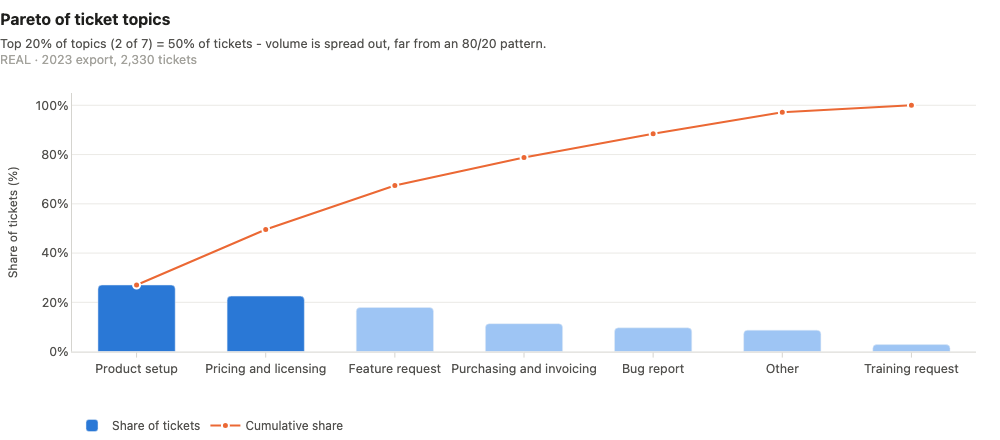

In [6]:
pareto = run_sql_file("07_topic_pareto.sql")
pd.testing.assert_frame_equal(pareto, D["kpi_topic_pareto"], check_dtype=False)        # = cached table
topics = pareto[pareto["level"] == "topic"].sort_values("rank")
n_top = check(int(np.ceil(0.2 * len(topics))), "pareto_top20pct_topics_n", 0)
check(topics["share"].head(n_top).sum(), "pareto_top20pct_topics_share")
print(f"Top {n_top} of {len(topics)} topics (top 20%) = {P(topics['share'].head(n_top).sum())} of tickets")
C.fig_topic_pareto(pareto, "topic")

**What this shows:** product setup and pricing & licensing together are 49.6% of tickets, and it takes four of the 7 topics to reach 79%. Demand is spread out, so automation has to work across several topics to matter.

### 2. Topic profile and complexity proxies [REAL]

`automation.topic_profile` re-run on the export and checked against the cached `topic_profile`. Lever and deflection columns are the assumptions from `config.yaml`.

In [7]:
fct = D["fct_tickets"]
profile = automation.topic_profile(fct, cfg)
pd.testing.assert_frame_equal(profile, D["topic_profile"], check_dtype=False)          # = cached table
spread = profile[["interactions_mean", "tier2_share", "resolution_median_h"]].agg(["min", "max"]).round(3)
print("Spread of the complexity proxies across topics:\n", spread.to_string())
profile[["topic", "tickets", "share", "interactions_mean", "tier2_share", "resolution_median_h", "complexity_index",
         "deflection_low", "deflection_base", "deflection_high", "lever"]].round(3)

Spread of the complexity proxies across topics:
      interactions_mean  tier2_share  resolution_median_h
min              4.147        0.177               18.638
max              5.092        0.293               23.449


,topic,tickets,share,interactions_mean,tier2_share,resolution_median_h,complexity_index,deflection_low,deflection_base,deflection_high,lever
0,Product setup,630,0.270,4.557,0.278,20.963,0.667,0.05,0.15,0.25,Guided setup articles + in-app onboarding checklist
1,Pricing and licensing,525,0.225,4.147,0.177,23.449,0.429,0.10,0.20,0.30,"Pricing & licensing FAQ + self-service license portal (keys, seats, renewals)"
2,Feature request,417,0.179,4.314,0.293,21.511,0.619,0.25,0.40,0.60,Route to product feedback portal with auto-acknowledgement (not support work)
3,Purchasing and invoicing,264,0.113,4.26,0.197,22.499,0.381,0.15,0.25,0.35,"Billing portal: invoice download, payment status, PO / address changes"
4,Bug report,225,0.097,4.521,0.258,18.638,0.524,0.00,0.00,0.05,None (needs investigation); status page for known issues only
5,Other,203,0.087,4.43,0.212,23.011,0.571,0.00,0.00,0.05,None identified
6,Training request,66,0.028,5.092,0.258,23.237,0.810,0.25,0.40,0.60,Training catalogue + booking form


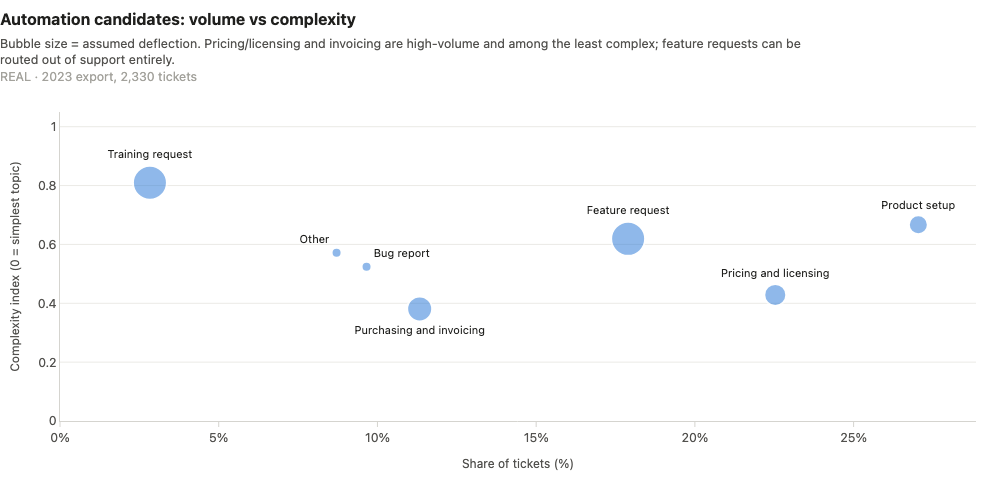

In [8]:
C.fig_automation_matrix(profile)

**What this shows:** the bottom right (high volume, low complexity) is where automation pays. Purchasing & invoicing and pricing & licensing are the two least complex topics and together a third of the volume; their requests are informational or transactional (invoices, licence keys, renewals), which suits self-service. Feature requests are not support work and can be routed to a product feedback portal. Product setup has the most volume but is the second most complex topic, so it gets a lower assumed rate. The proxies span a narrow range (mean interactions 4.1–5.1, tier-2 share 18%–29%, median resolution 19–23 h), so the index ranks topics but does not separate them strongly.

### 3. Deflection scenarios: tickets, agent-hours and FTE [ASSUMPTION × SYNTHETIC]

`automation_summary` and `automation_by_topic` come from `automation.automation_impact`. The base case is re-computed here with the dashboard's what-if function, `interactive.deflection_whatif`, which reuses the same requirement and roster code.

In [9]:
st = cfg["staffing"]
work_by_topic = D["synth_work_items"].groupby("topic")["service_s"].sum() / 3600 / (365 / 7)    # agent-hours per week
base_rates = dict(zip(profile["topic"], profile["deflection_base"]))
whatif = interactive.deflection_whatif(profile, work_by_topic, D["staff_demand"], st, base_rates)
check(whatif["deflected_share"], "auto_deflected_share_base")
check(whatif["hours_saved_week"], "auto_hours_saved_week_base", 1)
check(whatif["workload_reduction"], "auto_workload_reduction_base")
check(whatif["fte_before"], "staff_fte_current", 0)
summary = D["automation_summary"].set_index("level")
for level in ["low", "base", "high"]:
    check(summary.loc[level, "fte_freed"], f"auto_fte_freed_{level}", 0)
    check(summary.loc[level, "agent_hours_saved_week"], f"auto_hours_saved_week_{level}", 1)
print(f"Base case: {P(whatif['deflected_share'])} of tickets, {whatif['hours_saved_week']:.1f} agent-hours/week "
      f"({P(whatif['workload_reduction'])} of all agent work); FTE {whatif['fte_before']} -> {whatif['fte_after']} "
      f"(what-if: every hour scaled down) vs {summary.loc['base', 'fte_demand_shaped_after']} (pipeline: tickets removed)")
summary.round(3)

Base case: 19.7% of tickets, 85.7 agent-hours/week (19.4% of all agent work); FTE 23 -> 19 (what-if: every hour scaled down) vs 19 (pipeline: tickets removed)


,deflected_share_of_tickets,real_tickets_deflected_2023,scaled_tickets_deflected_year,agent_hours_saved_week,workload_reduction_share,fte_demand_shaped_before,fte_demand_shaped_after,fte_freed
level,,,,,,,,
low,0.105,244.35,4860.7,45.487,0.103,23,20,3
base,0.197,458.70,9132.0,85.707,0.194,23,19,4
high,0.308,718.60,14316.5,134.711,0.305,23,16,7


**Reading the table:** low / base / high deflection removes 10.5% / 19.7% / 30.8% of tickets, 45.5 / 85.7 / 134.7 agent-hours a week and 3 / 4 / 7 FTE of capacity at 20× scale. Capacity is worth ~€240k a year in the base case at the assumed FTE cost, but only if the freed hours are redeployed or rosters change; we do not count it as a saving.

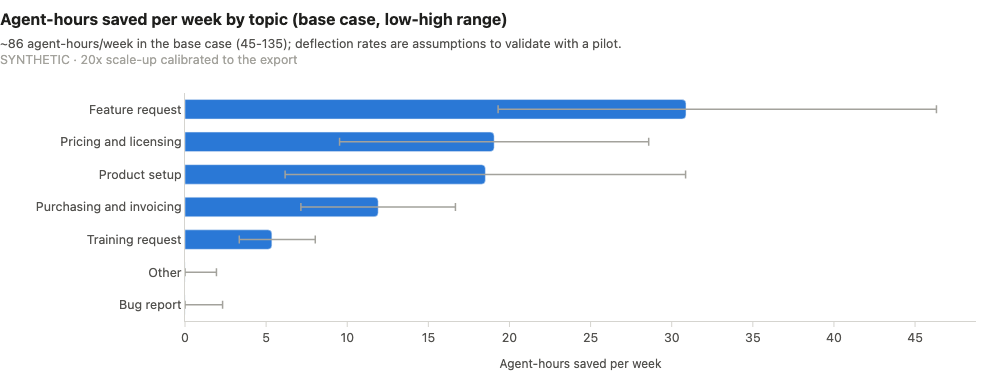

In [10]:
C.fig_hours_saved(D["automation_by_topic"])

**What this shows:** routing feature requests out of support is the largest single lever (30.9 agent-hours a week in the base case), followed by pricing & licensing (19.1) and product setup content (18.5). Bug reports and "Other" have no lever. The error bars are the low–high range of the deflection assumptions, not statistical uncertainty.

**Pilot scope.** The recommendation pilots only the levers for the three informational or transactional topics: self-service for pricing & licensing and purchasing & invoicing, and feedback-portal routing for feature requests. Same what-if function, base rates for those three topics, zero elsewhere:

Pilot scope: 14.5% of tickets, 62 agent-hours/week = 72% of the full base case


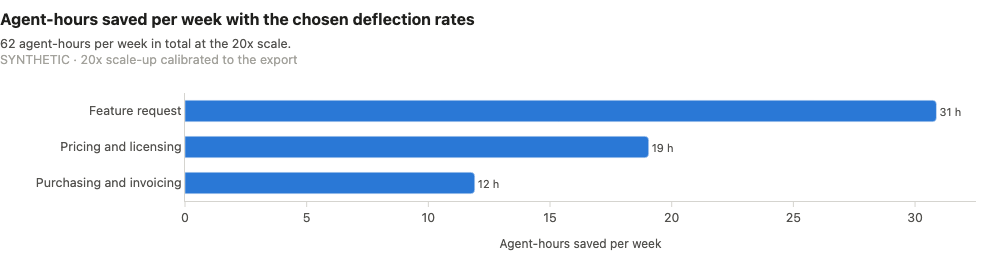

In [11]:
pilot_topics = ["Pricing and licensing", "Purchasing and invoicing", "Feature request"]
pilot = interactive.deflection_whatif(profile, work_by_topic, D["staff_demand"], st,
                                      {t: (r if t in pilot_topics else 0.0) for t, r in base_rates.items()})
print(f"Pilot scope: {P(pilot['deflected_share'])} of tickets, {pilot['hours_saved_week']:.0f} agent-hours/week "
      f"= {pilot['hours_saved_week'] / whatif['hours_saved_week']:.0%} of the full base case")
C.fig_deflection_whatif(pilot["by_topic"])

**What this shows:** the three pilot topics alone would deflect 14.5% of tickets and save about 62 agent-hours a week, roughly 72% of the full base case (computed here, not a key number). Product setup content and training booking could add the rest later.

### 4. Business case: hire vs re-roster vs automate [SYNTHETIC × ASSUMPTION]

All five options start from the same planning scenario: the 23-FTE desk at 20× volume with today's roster assumed weekday-weighted. Loaded from `business_options` (`business_case.options`). The response SLA columns are simulated on the synthetic year; costs are assumptions. Costs are re-computed with the dashboard's `interactive.costed_options` as a check. **These options move response SLA only.**

In [12]:
opts = D["business_options"]
c = cfg["cost"]
recosted = interactive.costed_options(opts, c["fte_annual_eur"], c["hire_one_off_eur"], c["automation_one_off_eur"],
                                      c["automation_annual_eur"])
assert (recosted["first_year_cost_eur"].round().to_numpy() == opts["first_year_cost_eur"].to_numpy()).all()
o = opts.set_index("option")
for option, key in [("0. Status quo", "bc_status_quo_sl"), ("A. Hire", "bc_hire_sl"), ("B. Re-roster", "bc_reroster_sl"),
                    ("C. Automate", "bc_automate_sl"), ("B + C", "bc_combined_sl")]:
    check(o.loc[option, "response_sl"], key)
    check(o.loc[option, "response_sl_sum"], key + "_sum")
check(o.loc["A. Hire", "annual_cost_change_eur"], "bc_hire_annual_cost_eur", 0)
check(o.loc["A. Hire", "one_off_cost_eur"], "bc_hire_one_off_eur", 0)
check(o.loc["A. Hire", "first_year_cost_eur"], "bc_hire_first_year_eur", 0)
check(o.loc["C. Automate", "first_year_cost_eur"], "bc_automation_first_year_eur", 0)
extra_fte = o.loc["A. Hire", "fte"] - o.loc["0. Status quo", "fte"]
print(f"Hire: {extra_fte:.1f} FTE x EUR {c['fte_annual_eur']:,} = EUR {extra_fte * c['fte_annual_eur']:,.0f}/year "
      f"+ {int(np.ceil(extra_fte))} hires x EUR {c['hire_one_off_eur']:,} one-off = EUR {o.loc['A. Hire', 'first_year_cost_eur']:,} in year one")
sq = o.loc["0. Status quo"]
table = o.assign(**{"gain optimistic (pts)": 100 * (o["response_sl"] - sq["response_sl"]),
                    "gain conservative (pts)": 100 * (o["response_sl_sum"] - sq["response_sl_sum"])})
table[["what_changes", "fte", "first_year_cost_eur", "response_sl", "response_sl_sum", "gain optimistic (pts)",
       "gain conservative (pts)", "process_sl"]].round({"response_sl": 4, "response_sl_sum": 4, "process_sl": 4,
                                                         "gain optimistic (pts)": 2, "gain conservative (pts)": 2})

Hire: 1.4 FTE x EUR 60,000 = EUR 84,000/year + 2 hires x EUR 5,000 one-off = EUR 94,000 in year one


,what_changes,fte,first_year_cost_eur,response_sl,response_sl_sum,gain optimistic (pts),gain conservative (pts),process_sl
option,,,,,,,,
0. Status quo,"Today's roster (assumed weekday-weighted), no change",23.0,0,0.8581,0.8259,0.00,0.00,0.8777
A. Hire,"Keep today's roster, add 7 weekend shifts (= 1.4 FTE; 2 whole hires)",24.4,94000,0.8764,0.8552,1.83,2.93,0.8777
B. Re-roster,"Move shifts from weekdays to weekends (workload-matched, near-flat roster)",23.0,0,0.8761,0.8469,1.80,2.10,0.8777
C. Automate,Self-service + routing deflects 20% of tickets; roster unchanged,23.0,65000,0.8771,0.8631,1.90,3.72,0.8794
B + C,"Re-roster now, add deflection over the quarter",23.0,65000,0.8790,0.8678,2.09,4.19,0.8794


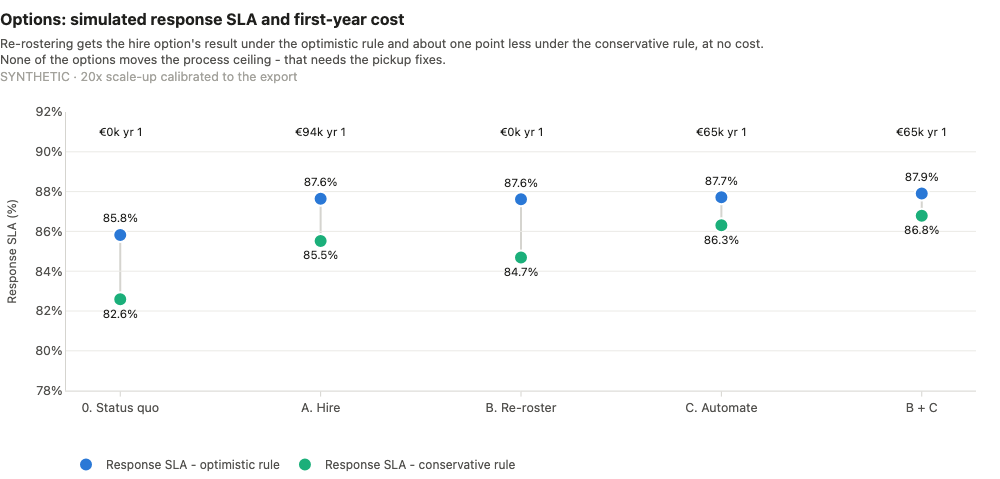

In [13]:
C.fig_options(opts)

**What this shows:** against the status quo (85.8% / 82.6%), hiring buys +1.8 / +2.9 points for €94k in year one; re-rostering +1.8 / +2.1 for nothing; automation +1.9 / +3.7 for €65k; both together +2.1 / +4.2 (optimistic / conservative rule). Re-rostering gets the whole optimistic gain of hiring and most of the conservative one. Automation helps a little more because it removes work, and it frees capacity for the resolution problem. No option can pass its process ceiling (87.8%, or 87.9% for C and B + C, whose deflected ticket population has a slightly different pickup mix), and B + C is already at it. Beyond that point only faster pickup helps.

### 5. The pickup fix: an unanswered-email alert [REAL × ASSUMPTION]

Response breaches are pickup failures, not queueing (notebook 02). The evidence is repeated here because the alert is designed around it.

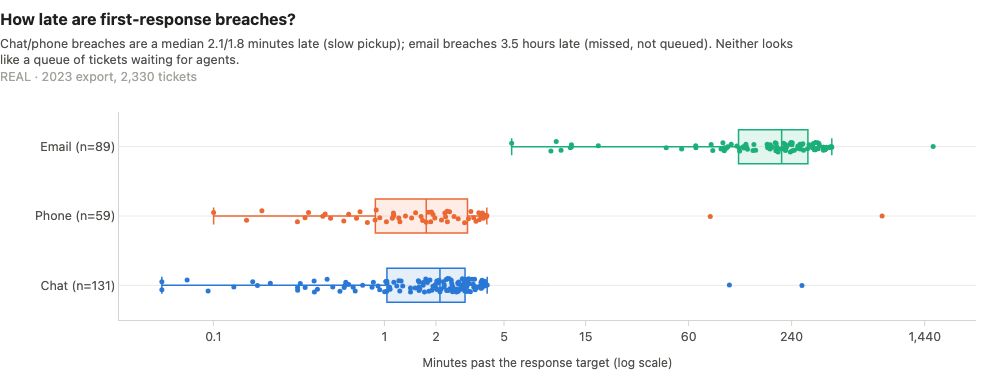

In [14]:
C.fig_breach_lateness(D["fct_tickets"])

**What this shows:** chat and phone breaches are about 2 minutes late; email breaches a median 3.5 hours late. Only 10% of email breaches are near misses (at most 60 minutes late), and 14 were never answered. These emails were missed, not queued, so a reminder before the 60-minute deadline targets them directly.

In [15]:
lever = rca.email_alert_lever(D["fct_tickets"])
pd.testing.assert_frame_equal(lever["table"], D["rca_email_alert"], check_dtype=False)        # = cached table
check(lever["email_breaches"], "email_breaches", 0)
check(lever["evaluable"], "response_evaluable", 0)
check(lever["response_sl_now"], "response_sla_2023")
for (_, row), key in zip(lever["table"].iterrows(), ["low", "base", "high"]):
    check(row["uplift_pp"], f"email_alert_uplift_pp_{key}", 2)
    dashboard = interactive.email_alert_sl(lever["response_sl_now"], lever["email_breaches"], lever["evaluable"],
                                           row["catch_rate"])
    assert abs(dashboard - row["response_sl_after"]) < 1e-12          # dashboard what-if = pipeline formula
check(lever["table"]["response_sl_after"].iloc[1], "email_alert_response_sla_base")
check(lever["table"]["response_sl_after"].iloc[2], "email_alert_response_sla_high")
print(f"{lever['email_breaches']} email breaches among {lever['evaluable']:,} tickets with a response outcome; "
      f"response SLA now {P(lever['response_sl_now'])}")
lever["table"].round(4)

103 email breaches among 2,328 tickets with a response outcome; response SLA now 87.2%


,catch_rate,breaches_avoided,response_sl_after,uplift_pp
0,0.25,25.75,0.8835,1.1061
1,0.50,51.50,0.8945,2.2122
2,0.75,77.25,0.9056,3.3183


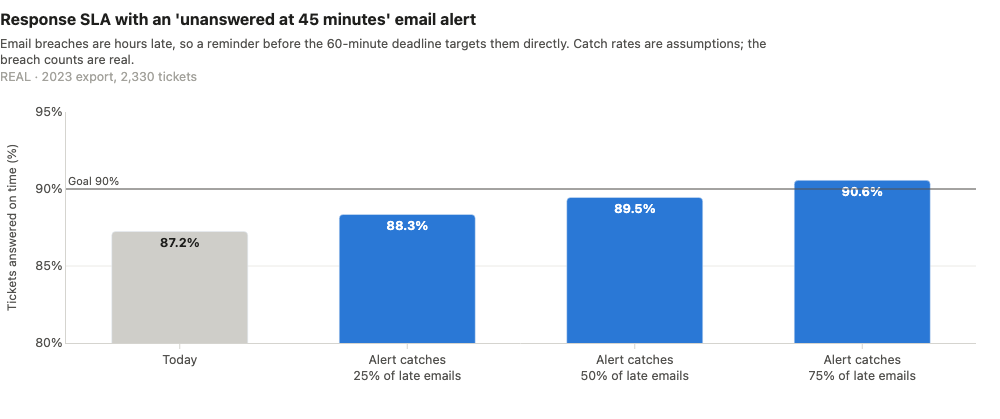

In [16]:
C.fig_email_alert(D["rca_email_alert"], kn["response_sla_2023"], cfg["sla"]["goal_attainment"])

**What this shows:** if the alert got half of the late emails answered in time, response SLA would rise from 87.2% to 89.5% (+2.2 points); at a 75% catch rate it would reach 90.6%. The breach counts are real; the catch rate is the unknown, so this is a pilot to measure, not a forecast. It is kept out of the options above: it acts on real pickup behaviour, which the simulated options hold fixed, and adding an unmeasured catch rate to simulated gains would overstate both.

## Limitations

- **Deflection rates are assumptions,** not measurements. Only a pilot can measure them, and weak content sends contacts back to agents.
- **The complexity proxies are weak in this export.** Interactions, tier-2 share and resolution time differ little between topics (interaction counts are near-uniform in the export), so the ranking rests mainly on volume and on whether a request is informational or transactional.
- **Deflection removes whole tickets.** Partial deflection (a customer who reads an article and still writes in) and re-contacts are not modelled. Topics are spread evenly over the week in the synthetic data, so deflection lowers every hour by about the same share.
- **Hours and FTE are at 20× scale [SYNTHETIC].** The FTE freed is capacity in a planning scenario, realised only if rosters or work allocation change. It is not a saving.
- **Costs are assumptions to confirm with Finance.** Hiring lead time, ramp-up and attrition are not modelled; automation costs are rough estimates.
- **The options move response SLA only.** Resolution SLA, the one that fell, needs the stale-ticket sweep and the slow-path investigation (notebook 03).
- **Email alert:** the catch rate is unknown, and most email breaches are hours late, so the alert helps only if someone owns the alert queue (alert fatigue is the main risk). The uplift is computed on the real export, not simulated at 20×, and is not added to the options.

## Recommendations

- **Support Director: no headcount request this quarter; prefer re-rostering to hiring, after WFM confirms today's roster.** Impact [SYNTHETIC]: re-rostering buys +1.8 (optimistic) to +2.1 (conservative) points of response SLA at no cost; hiring buys at most +1.4 more for ~€94k in year one. Measure: response SLA by hour of week before and after the roster change. Risk: today's real roster may not be weekday-weighted (notebook 04).
- **Self-service / knowledge owner: pilot self-service for pricing & licensing and purchasing & invoicing, and route feature requests to a feedback portal.** Impact [ASSUMPTION × SYNTHETIC]: the full base case deflects 20% of tickets, ~86 agent-hours a week, ~4 FTE of capacity (range 3–7) to redeploy to the stale-ticket sweep and resolution work or to absorb growth. Measure: tickets per topic per week vs the 2023 baseline; self-service success rate; CSAT on deflected topics. Risk: deflection rates are assumptions; weak content sends contacts back to agents.
- **Team leads + support-tooling owner: pilot a 45-minute "unanswered email" alert, and push routing for chat/phone.** Impact [REAL × ASSUMPTION]: +2.2 points of response SLA if half of the late emails are caught; no SLA credit until the catch rate is measured. Measure: share of emails answered within 60 minutes; alerts fired vs answered within 15 minutes. Risk: alert fatigue; only 10% of email breaches are near misses, so the alert must trigger action, not just a notification.
- **Finance business partner: confirm the cost assumptions** (€60,000 per FTE per year, €5,000 per hire, €40,000 one-off + €25,000 a year for automation) before the options go to the VP. Risk: low for the hire-vs-re-roster choice (re-rostering costs nothing either way); the automation case depends on them.